# Project Part 1 — Speed

A replication, on September 2026 data, of Scholtus & van Dijk (2012), *High-Frequency
Technical Trading: The Importance of Speed*. Three technical signals are run on three
securities, with orders executed 0 ms, 100 ms or 1 s after the signal fires, and the
P&L of each combination is tracked on a \$1,000,000 book.

| step | what | where |
|---|---|---|
| a | 2 equities + 1 FX pair | AAPL (liquid), GPRO (less liquid), CME Euro FX futures `6E` |
| b | one-month period | September 2026, 21 trading days |
| c | 2 paper signals + 1 own | MA crossover, On-Balance Volume, order-book imbalance |
| d | execution delays | 0 ms, 100 ms, 1 s (plus a finer grid for part f) |
| e | total return on \$1M | 27 P&L reports (3 securities × 3 signals × 3 delays) |
| f | cost of delay | the paper's Figure 6, per security and signal |

Data come from `pull_data.py` (Databento MBP-1: every top-of-book update and every
trade). Every figure in this notebook is also written to `output/`, and the tables to
`output/*.csv`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import to_rgb

PROJECT = Path.cwd() if (Path.cwd() / "pull_data.py").exists() else Path.cwd() / "project"
PARQUET = PROJECT / "data" / "parquet"
OUT = PROJECT / "output"
OUT.mkdir(exist_ok=True)

SECURITIES = {  # label -> file symbol
    "AAPL": "AAPL",
    "GPRO": "GPRO",
    "6E (EUR/USD)": "6E.v.0",
}
SIGNALS = ["MA", "OBV", "OBI"]
DELAYS = [0, 100, 1000]                              # ms, the three required
DELAY_GRID = [0, 10, 20, 50, 100, 200, 500, 1000]    # ms, the paper's Figure 6 x-axis
BOOK = 1_000_000

# trading window: signals warm up from 09:30, positions only 09:40-15:50, flat at 15:50
TRADE_START, TRADE_END = "09:40", "15:50"

# signal parameters, the same for all three securities (chosen for turnover, not return)
SHORT, LONG = "60s", "600s"   # MA / OBV windows
MA_BAND = 1.0                 # MA band, in units of the current quoted spread
OBV_K = 0.05                  # OBV band, as a fraction of volume traded in the long window
OBI_WINDOW, OBI_TH = "10s", 0.5

# chart styling: one hue per signal (validated categorical slots 1-3); delay = lightness + dash
SIG_COLOR = {"MA": "#2a78d6", "OBV": "#eb6834", "OBI": "#1baf7a"}
DELAY_STYLE = {0: (1.0, "-"), 100: (0.65, "--"), 1000: (0.4, ":")}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "lines.linewidth": 1.8, "font.size": 9, "axes.titlesize": 10, "legend.frameon": False,
})
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")


def shade(color, strength):
    """Blend a hue toward white: strength 1 = full colour, lower = lighter."""
    return tuple(1 - strength * (1 - c) for c in to_rgb(color))


def save(fig, name):
    fig.savefig(OUT / f"{name}.png")
    plt.show()


def ms_label(d):
    return "1 s" if d == 1000 else f"{d} ms"

## Loading and the backtest engine

Each security-day is one Parquet file of MBP-1 records. Only the fields needed are
kept, crossed or empty books are dropped, and the clock is **`ts_event`** (the
exchange's timestamp, in nanoseconds) converted to New York time.

**Execution model** (used in parts d–f):

* Each signal maps every event to a target position of +1 (long the full book), −1
  (short the full book) or 0, and holds that position until the opposite signal fires.
* A change in target at event time *t* sends a marketable order that fills at the
  quote prevailing at *t + delay*: buys at the ask, sells at the bid. With 0 delay it
  fills on the very quote that triggered it.
* New positions are taken only between 09:40 and 15:50. Everything is closed at 15:50
  (plus the delay), so no position is held overnight.
* Each holding period earns *r = pos × (exit / entry − 1)*, and the book compounds
  trade by trade and day by day.
* The spread is the only trading cost: there are no fees, and every order fills in
  full at the touch, whatever its size. That's generous for GPRO, where \$1M is
  ~750k shares against a few thousand at the touch.
* The same legs are also priced at the **mid**, which gives the return before
  spread costs. That separates whether a signal predicts anything from whether it
  can pay the spread.

In [2]:
COLS = ["ts_event", "action", "price", "size", "bid_px_00", "ask_px_00", "bid_sz_00", "ask_sz_00"]


def load_day(symbol, day):
    df = pd.read_parquet(next(PARQUET.glob(f"*_{symbol}_{day}.parquet")), columns=COLS)
    df = df.sort_values("ts_event", kind="stable").reset_index(drop=True)
    ok = (df.bid_px_00 > 0) & (df.ask_px_00 > df.bid_px_00) & (df.ask_px_00 < 1.5 * df.bid_px_00)
    df = df[ok].astype({"bid_sz_00": float, "ask_sz_00": float, "size": float})
    df.index = pd.DatetimeIndex(df.ts_event.dt.tz_convert("America/New_York").dt.tz_localize(None), name="t")
    df["mid"] = (df.bid_px_00 + df.ask_px_00) / 2
    df["spread"] = df.ask_px_00 - df.bid_px_00
    return df


def signals(df):
    """Target position (+1 / -1 / 0) at every event, for each of the three signals."""
    mid, spr = df.mid, df.spread
    hold = lambda long, short: np.select([long, short], [1.0, -1.0], np.nan)  # nan = keep last

    # MA: short vs long moving average of the mid, with a band of one quoted spread
    # (the 600 s average spread, so the rule doesn't fire just because the spread ticks in)
    ms, ml = mid.rolling(SHORT).mean(), mid.rolling(LONG).mean()
    band = MA_BAND * spr.rolling(LONG).mean()
    ma = hold(ms > ml + band, ms < ml - band)

    # OBV: cumulative trade volume signed by the tick direction of the trade price,
    # short vs long moving average, band = 5% of volume traded over the long window
    is_trade = (df.action == "T").values
    px = df.price.values[is_trade]
    signed = np.zeros(len(df))
    signed[is_trade] = np.sign(np.diff(px, prepend=px[0])) * df["size"].values[is_trade]
    obv = pd.Series(np.cumsum(signed), index=df.index)
    gap = obv.rolling(SHORT).mean() - obv.rolling(LONG).mean()
    band = OBV_K * pd.Series(np.abs(signed), index=df.index).rolling(LONG).sum()
    obv_sig = hold(gap > band, gap < -band)

    # OBI (own): depth imbalance at the touch, averaged over 10 s
    imb = ((df.bid_sz_00 - df.ask_sz_00) / (df.bid_sz_00 + df.ask_sz_00)).rolling(OBI_WINDOW).mean()
    obi = hold(imb > OBI_TH, imb < -OBI_TH)

    out = pd.DataFrame({"MA": ma, "OBV": obv_sig, "OBI": obi}, index=df.index).ffill().fillna(0)
    return out, {"ma_s": ms, "ma_l": ml, "obv": obv, "imb": imb}


def legs(df, target, delay_ms):
    """Holding periods for one signal and one delay; returns one row per non-flat leg."""
    ts = df.index.values.astype("int64")
    day = df.index[0].normalize()
    t0 = (day + pd.Timedelta(f"{TRADE_START}:00")).value
    t1 = (day + pd.Timedelta(f"{TRADE_END}:00")).value

    idx = np.flatnonzero((ts >= t0) & (ts < t1))
    s = target[idx]
    chg = np.r_[True, s[1:] != s[:-1]]
    trig = np.r_[idx[chg], -1]                   # -1 marks the forced 15:50 exit
    sig_t = np.r_[ts[idx[chg]], t1]
    pos = np.r_[s[chg], 0.0]
    keep = np.r_[True, pos[1:] != pos[:-1]]
    trig, sig_t, pos = trig[keep], sig_t[keep], pos[keep]

    d = delay_ms * 1_000_000
    ex = np.searchsorted(ts, sig_t + d, side="right") - 1
    if delay_ms == 0:
        ex = np.where(trig >= 0, trig, ex)       # fill on the triggering quote itself

    bid, ask, mid = df.bid_px_00.values, df.ask_px_00.values, df.mid.values
    p, a, b = pos[:-1], ex[:-1], ex[1:]
    entry = np.where(p > 0, ask[a], bid[a])
    exit_ = np.where(p > 0, bid[b], ask[b])
    out = pd.DataFrame({
        "t_signal": pd.to_datetime(sig_t[:-1]), "t_exit": pd.to_datetime(sig_t[1:] + d),
        "pos": p,
        "r": p * (exit_ / entry - 1),
        "r_mid": p * (mid[b] / mid[a] - 1),
        "trig": trig[:-1],
    })
    return out[out.pos != 0]

Run everything, one security-day at a time (a month of AAPL is ~20M rows, so the
month is never held in memory at once). For each security-day this collects:

* descriptive stats: events, trades, spread and volatility, for part (a)
* a 1-minute mid series, for the price charts
* the legs of every signal × delay on the full delay grid, for parts (e) and (f)
* the mid move between each signal and its delayed execution, used in the commentary

In [3]:
DAYS = sorted({p.stem.rsplit("_", 1)[1] for p in PARQUET.glob("*.parquet")})

stats, minute_mid, all_legs, drift = [], [], [], []
for label, sym in SECURITIES.items():
    for day in DAYS:
        df = load_day(sym, day)
        tgt, aux = signals(df)

        sess = df.between_time(TRADE_START, TRADE_END)
        m1 = sess.mid.resample("1min").last().dropna()
        r1 = np.log(m1).diff().dropna()
        n_tr = int((df.action == "T").sum())
        secs = (df.index[-1] - df.index[0]).total_seconds()
        stats.append(dict(
            security=label, day=day, events=len(df), trades=n_tr,
            events_per_sec=len(df) / secs,
            med_gap_ms=np.median(np.diff(df.index.values).astype("int64")) / 1e6,
            mid=sess.mid.mean(), spread_bp=(sess.spread / sess.mid).median() * 1e4,
            open=m1.iloc[0], close=m1.iloc[-1],
            vol_1min_bp=r1.std() * 1e4,
            trend_eff=abs(np.log(m1.iloc[-1] / m1.iloc[0])) / r1.abs().sum(),
        ))
        minute_mid.append(m1.rename(label).to_frame().assign(day=day))

        ts, mid = df.index.values.astype("int64"), df.mid.values
        for sig in SIGNALS:
            target = tgt[sig].values
            for d in DELAY_GRID:
                lg = legs(df, target, d).assign(security=label, signal=sig, delay=d, day=day)
                all_legs.append(lg.drop(columns="trig"))
                if d == 0:
                    # entry fills only: mid move in the direction of the trade, signal -> delay,
                    # and the fill price (ask for a buy, bid for a sell), split into the two parts
                    i0, p = lg.trig.values, lg.pos.values
                    side_px = lambda k: np.where(p > 0, df.ask_px_00.values[k], df.bid_px_00.values[k])
                    for dd in DELAY_GRID[1:]:
                        j = np.searchsorted(ts, ts[i0] + dd * 1_000_000, side="right") - 1
                        drift.append(pd.DataFrame(dict(
                            security=label, signal=sig, delay=dd,
                            drift_bp=p * (mid[j] / mid[i0] - 1) * 1e4,
                            shortfall_bp=p * (side_px(j) / side_px(i0) - 1) * 1e4,
                            moved=mid[j] != mid[i0])))
        del df, tgt, aux

stats = pd.DataFrame(stats)
minute_mid = pd.concat(minute_mid)
all_legs = pd.concat(all_legs, ignore_index=True)
drift = pd.concat(drift, ignore_index=True)
print(f"{len(DAYS)} days, {len(all_legs):,} legs")

21 days, 74,568 legs


## (a) Securities

| | security | venue / feed | why |
|---|---|---|---|
| liquid equity | **AAPL** | Nasdaq TotalView-ITCH (`XNAS.ITCH`) | one of the most traded stocks; 1-cent spread on a ~\$330 price |
| less liquid equity | **GPRO** | Nasdaq TotalView-ITCH (`XNAS.ITCH`) | ~\$1.30 stock; the 1-cent tick is a ~75 bp spread |
| FX | **EUR/USD**, via CME Euro FX futures **6E** | CME Globex MDP 3.0 (`GLBX.MDP3`) | most liquid FX pair; nanosecond exchange timestamps |

Notes on the data, worth stating in the write-up:

* **Equity quotes are Nasdaq's top of book, not the consolidated NBBO.** `XNAS.ITCH`
  is Nasdaq-only. The paper also used Nasdaq data.
* **The FX pair is a futures contract, not spot.** Spot EUR/USD trades OTC (EBS,
  Reuters) and isn't available on Databento. 6E is a contract on 125,000 EUR,
  quoted in USD per EUR, and tracks spot closely. The continuous series `6E.v.0`
  rolls from the September contract (6EU6) to December (6EZ6) between Sep 11 and
  Sep 14. That falls overnight, and positions are flat overnight, so the roll never
  enters a return.
* Three very different event rates: the table shows how often each market updates.

In [4]:
summary = stats.groupby("security", sort=False).agg(
    price=("mid", "mean"), spread_bp=("spread_bp", "median"),
    events_per_day=("events", "mean"), trades_per_day=("trades", "mean"),
    events_per_sec=("events_per_sec", "mean"), median_gap_ms=("med_gap_ms", "median"),
    vol_1min_bp=("vol_1min_bp", "mean"),
)
summary.to_csv(OUT / "a_security_summary.csv")
summary.style.format({
    "price": "{:,.4f}", "spread_bp": "{:.2f}", "events_per_day": "{:,.0f}", "trades_per_day": "{:,.0f}",
    "events_per_sec": "{:,.1f}", "median_gap_ms": "{:.3f}", "vol_1min_bp": "{:.2f}",
})

,price,spread_bp,events_per_day,trades_per_day,events_per_sec,median_gap_ms,vol_1min_bp
security,,,,,,,
AAPL,331.0979,0.90,"944,372","135,531",40.4,0.032,5.83
GPRO,1.3826,76.05,"56,589","7,665",2.4,2.019,38.82
6E (EUR/USD),1.1530,0.43,"621,094","14,549",26.5,0.132,0.87


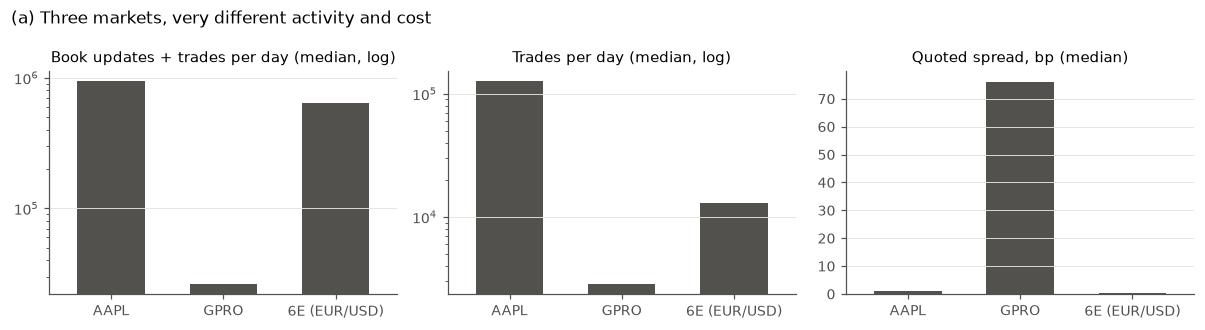

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3), sharey=False)
for ax, col in zip(axes, ["events", "trades", "spread_bp"]):
    piv = stats.pivot(index="day", columns="security", values=col)[list(SECURITIES)]
    piv.median().plot.bar(ax=ax, color=MUTED, width=0.6, rot=0)
    ax.set_yscale("log" if col != "spread_bp" else "linear")
    ax.set_title({"events": "Book updates + trades per day (median, log)",
                  "trades": "Trades per day (median, log)",
                  "spread_bp": "Quoted spread, bp (median)"}[col])
    ax.set_xlabel("")
    ax.grid(axis="x", visible=False)
fig.suptitle("(a) Three markets, very different activity and cost", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
save(fig, "a_activity")

## (b) Period: September 2026

21 trading days, Sep 1–30, with Labor Day (Sep 7) excluded. Data are pulled 09:30–16:00
ET. The first 10 minutes only warm up the 600-second lookbacks, and trading runs
09:40–15:50, as in the paper. The futures trade nearly 24 hours a day, but they're
cut to the same window so all three are compared over the same hours.

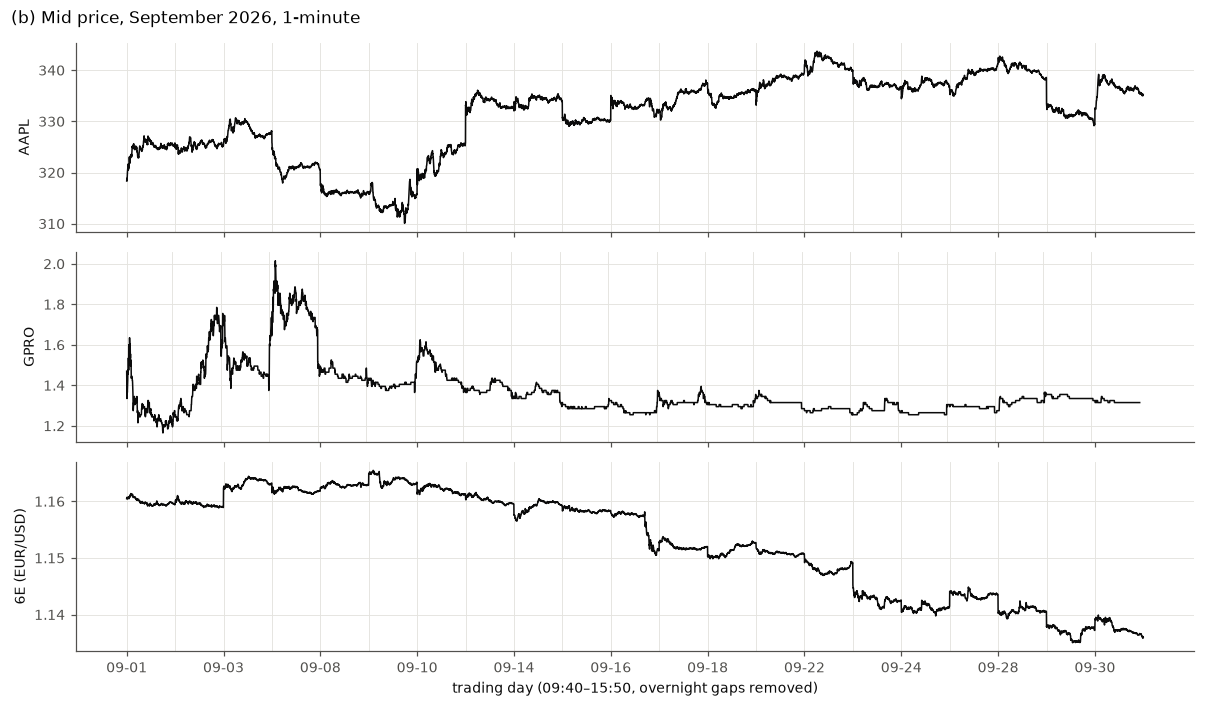

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(11, 6.5), sharex=True)
for ax, label in zip(axes, SECURITIES):
    s = minute_mid[[label, "day"]].dropna()
    x = np.arange(len(s))
    ax.plot(x, s[label].values, color=INK, lw=1)
    ax.set_ylabel(label)
    starts = np.flatnonzero(s.day.ne(s.day.shift()).values)
    for i in starts:
        ax.axvline(i, color=GRID, lw=0.6, zorder=0)
    ax.grid(axis="x", visible=False)
axes[-1].set_xticks(starts[::2], [d[5:] for d in s.day.iloc[starts[::2]]])
axes[-1].set_xlabel("trading day (09:40–15:50, overnight gaps removed)")
fig.suptitle("(b) Mid price, September 2026, 1-minute", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
save(fig, "b_prices")

In [7]:
daily = stats.pivot(index="day", columns="security", values="close")[list(SECURITIES)]
month_ret = (daily.iloc[-1] / stats.pivot(index="day", columns="security", values="open")[list(SECURITIES)].iloc[0] - 1)
print("Buy-and-hold over the month (first 09:40 mid to last 15:50 mid):")
print((month_ret * 100).round(2).astype(str) + "%")

Buy-and-hold over the month (first 09:40 mid to last 15:50 mid):
security
AAPL              5.31%
GPRO            -10.54%
6E (EUR/USD)     -2.11%
dtype: str


## (c) Signals

Two rules from the paper and one of our own. All are computed in event time on every
book update, with clock-time lookbacks, so a market that updates more often simply
gets more observations per window. Within each rule's neutral band the previous
position is kept, which stops the rule flipping every time the band is crossed.

**1. Moving-average crossover (MA)** — the paper's main trend rule.
Long when the 60 s average mid is above the 600 s average by more than one quoted
spread; short when it is below by more than one spread. The spread band is the
Brock-Lakonishok-LeBaron band filter, scaled to the asset, so the rule only fires
when the trend is at least as big as the cost of acting on it.

**2. On-Balance Volume (OBV)** — the paper's volume rule.
OBV adds a trade's volume when its price ticks up and subtracts it when the price
ticks down. Long when the 60 s average of OBV is above the 600 s average by more than
5% of the volume traded in the last 600 s; short when it is below by the same amount.
The rule buys when volume is flowing in on upticks.

**3. Order-book imbalance (OBI)** — our own.
*I = (bid size − ask size) / (bid size + ask size)* at the touch, averaged over 10 s.
Long when *I* > 0.5, short when *I* < −0.5. A deep bid against a thin ask tends to
precede an uptick, because the thin side is the one that gets depleted first.
This rule works on a horizon of seconds rather than minutes, so it should be much
more sensitive to execution delay than the two paper rules. That makes it a useful
contrast for part (f).

The chart below shows half an hour of AAPL, chosen as a window in which all three signals trade.

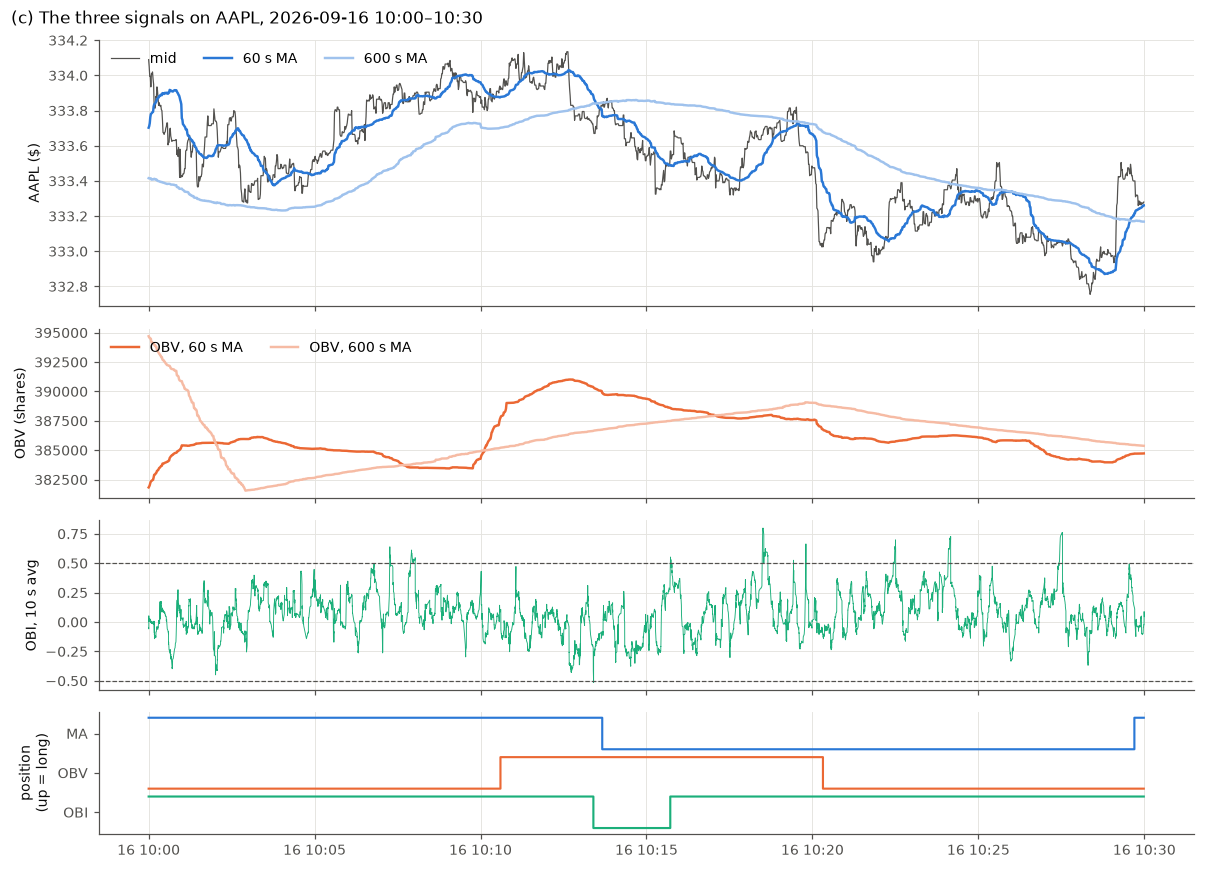

In [8]:
# reload the AAPL day on which OBI trades most, so all three signals are visible
ex_day = all_legs.query("security == 'AAPL' and signal == 'OBI' and delay == 0").day.value_counts().idxmax()
df_ex = load_day("AAPL", ex_day)
tgt_ex, aux_ex = signals(df_ex)
# show the half hour (after 10:00) in which every signal changes position: max of the min count
SPAN = pd.Timedelta("30min")
changes = tgt_ex.diff().ne(0).between_time("10:00", "15:19:59").resample(SPAN).sum()
h0 = changes.min(axis=1).idxmax()
win = slice(h0, h0 + SPAN)
one_s = lambda s: s.loc[win].resample("1s").last().ffill()

fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True,
                         gridspec_kw={"height_ratios": [2.2, 1.4, 1.4, 1]})
ax = axes[0]
ax.plot(one_s(df_ex.mid), color=MUTED, lw=0.8, label="mid")
ax.plot(one_s(aux_ex["ma_s"]), color=SIG_COLOR["MA"], lw=1.6, label="60 s MA")
ax.plot(one_s(aux_ex["ma_l"]), color=shade(SIG_COLOR["MA"], 0.45), lw=1.6, label="600 s MA")
ax.set_ylabel("AAPL ($)")
ax.legend(loc="upper left", ncol=3)

ax = axes[1]
obv = aux_ex["obv"]
ax.plot(one_s(obv.rolling(SHORT).mean()), color=SIG_COLOR["OBV"], lw=1.6, label="OBV, 60 s MA")
ax.plot(one_s(obv.rolling(LONG).mean()), color=shade(SIG_COLOR["OBV"], 0.45), lw=1.6, label="OBV, 600 s MA")
ax.set_ylabel("OBV (shares)")
ax.legend(loc="upper left", ncol=2)

ax = axes[2]
ax.plot(aux_ex["imb"].loc[win], color=SIG_COLOR["OBI"], lw=0.6)  # every event, so threshold crossings show
for th in (OBI_TH, -OBI_TH):
    ax.axhline(th, color=MUTED, lw=0.8, ls="--")
ax.set_ylabel("OBI, 10 s avg")

ax = axes[3]
for k, sig in enumerate(SIGNALS):
    ax.step(one_s(tgt_ex[sig]).index, one_s(tgt_ex[sig]) * 0.8 + 2 * (2 - k), where="post",
            color=SIG_COLOR[sig], lw=1.4)
ax.set_yticks([4, 2, 0], SIGNALS)
ax.set_ylabel("position\n(up = long)")
ax.grid(axis="y", visible=False)
fig.suptitle(f"(c) The three signals on AAPL, {ex_day} {h0:%H:%M}–{h0 + SPAN:%H:%M}",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout()
save(fig, "c_signals_example")

In [9]:
turnover = (all_legs[all_legs.delay == 0].groupby(["security", "signal"], sort=False)
            .size().div(len(DAYS)).unstack()[SIGNALS])
print("Round trips per day (0 delay):")
turnover.round(1)

Round trips per day (0 delay):


signal,MA,OBV,OBI
security,,,
AAPL,52.5000,12.2000,29.1000
GPRO,7.2000,28.7000,46.5000
6E (EUR/USD),34.7000,30.7000,202.3000


## (d) Execution delays

Delays of **0 ms, 100 ms and 1 s** are applied exactly as described in the engine
section: the order fills on the quote standing at *signal time + delay*. The signal,
and therefore the intended position, is identical across delays. Only the fill
price changes, so any difference in P&L is purely the cost of being slow.

Part (f) also runs the paper's full grid (0, 10, 20, 50, 100, 200, 500 ms, 1 s) to
draw the Figure 6 curve. The chart below shows why delay matters: how far, and in
which direction, the mid has moved between the signal and the fill. A positive
number means the price ran away from the trader, so a delayed order pays more.

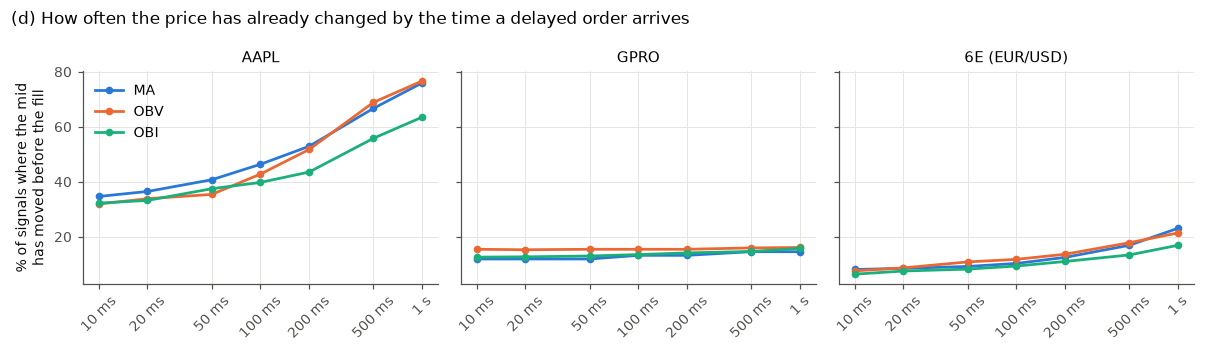

In [10]:
dr = drift.groupby(["security", "signal", "delay"]).agg(
    adverse_bp=("drift_bp", "mean"), shortfall_bp=("shortfall_bp", "mean"),
    p_moved=("moved", "mean")).reset_index()
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
for ax, label in zip(axes, SECURITIES):
    for sig in SIGNALS:
        s = dr[(dr.security == label) & (dr.signal == sig)]
        ax.plot(s.delay, s.p_moved * 100, color=SIG_COLOR[sig], marker="o", ms=4, label=sig)
    ax.set_xscale("log")
    ax.set_xticks(DELAY_GRID[1:], [ms_label(d) for d in DELAY_GRID[1:]], rotation=45)
    ax.minorticks_off()
    ax.set_title(label)
axes[0].set_ylabel("% of signals where the mid\nhas moved before the fill")
axes[0].legend()
fig.suptitle("(d) How often the price has already changed by the time a delayed order arrives",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout()
save(fig, "d_price_moved_before_fill")

## (e) Total returns on \$1,000,000

One P&L report for each security × signal × delay: 27 in all. The spec counts 18;
the full 3 × 3 × 3 grid is shown here. The book starts at \$1,000,000, is fully
invested long or short while a signal is active, and compounds over the month.

Columns:
* `final_value`, `pnl`, `return_pct`: book value and return after spread costs
* `mid_return_pct`: the same trades priced at the mid, before spread costs
* `round_trips`, `win_rate`, `avg_trade_bp`: per-trade statistics
* `sharpe`: annualised, from the 21 daily returns
* `max_dd_pct`: worst peak-to-trough fall of the trade-by-trade equity curve

In [11]:
def report(g):
    g = g.sort_values("t_exit")
    eq = BOOK * np.cumprod(1 + g.r.values)
    day_r = g.groupby("day").r.apply(lambda r: np.prod(1 + r) - 1).reindex(DAYS, fill_value=0.0)
    peak = np.maximum.accumulate(np.r_[BOOK, eq])
    final = eq[-1] if len(eq) else BOOK
    return pd.Series({
        "final_value": final, "pnl": final - BOOK,
        "return_pct": (final / BOOK - 1) * 100,
        "mid_return_pct": (np.prod(1 + g.r_mid.values) - 1) * 100,
        "round_trips": len(g), "win_rate": (g.r > 0).mean() * 100 if len(g) else np.nan,
        "avg_trade_bp": g.r.mean() * 1e4 if len(g) else np.nan,
        "sharpe": day_r.mean() / day_r.std() * np.sqrt(252) if day_r.std() > 0 else np.nan,
        "max_dd_pct": ((np.r_[BOOK, eq] / peak).min() - 1) * 100,
    })


reports = (all_legs.groupby(["security", "signal", "delay"], sort=False)
           .apply(report, include_groups=False))
reports = reports.reindex(pd.MultiIndex.from_product([list(SECURITIES), SIGNALS, DELAY_GRID],
                                                     names=["security", "signal", "delay"]))
reports.to_csv(OUT / "e_pnl_reports_full_grid.csv")
pnl = reports.loc[(slice(None), slice(None), DELAYS), :]
pnl.to_csv(OUT / "e_pnl_reports.csv")
pnl.style.format({
    "final_value": "${:,.0f}", "pnl": "${:,.0f}", "return_pct": "{:.2f}%", "mid_return_pct": "{:.2f}%",
    "round_trips": "{:,.0f}", "win_rate": "{:.1f}%", "avg_trade_bp": "{:.2f}", "sharpe": "{:.2f}",
    "max_dd_pct": "{:.2f}%",
})

The equity curves, one panel per security × signal. The colour is the signal and gets
lighter (and dashed) as the delay grows. Each panel has its own y-scale, because the
scale differs a lot between assets.

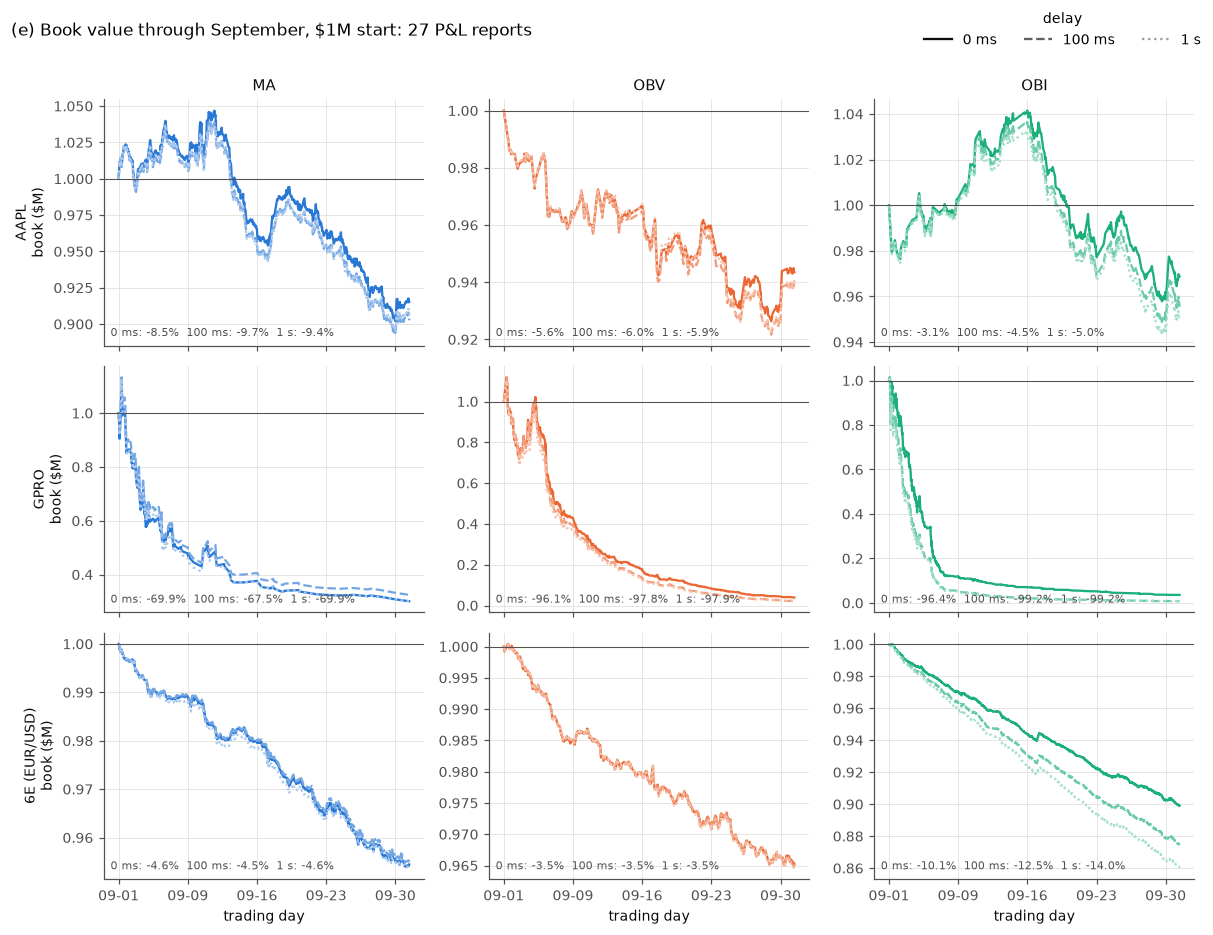

In [12]:
fig, axes = plt.subplots(3, 3, figsize=(11, 8.5), sharex=True)
day_pos = {d: i for i, d in enumerate(DAYS)}
sess_ns = (pd.Timedelta(f"{TRADE_END}:00") - pd.Timedelta(f"{TRADE_START}:00")).value
for i, label in enumerate(SECURITIES):
    for j, sig in enumerate(SIGNALS):
        ax = axes[i, j]
        for d in DELAYS:
            g = all_legs[(all_legs.security == label) & (all_legs.signal == sig) & (all_legs.delay == d)]
            g = g.sort_values("t_exit")
            intraday = (g.t_exit - g.t_exit.dt.normalize() - pd.Timedelta(f"{TRADE_START}:00")) / pd.Timedelta(sess_ns)
            x = np.r_[0, g.day.map(day_pos).values + intraday.clip(0, 1).values]
            y = np.r_[BOOK, BOOK * np.cumprod(1 + g.r.values)] / 1e6
            strength, ls = DELAY_STYLE[d]
            ax.plot(x, y, color=shade(SIG_COLOR[sig], strength), ls=ls, lw=1.5)
        ax.axhline(1, color=MUTED, lw=0.7)
        if i == 0:
            ax.set_title(sig, color=INK)
        if j == 0:
            ax.set_ylabel(f"{label}\nbook ($M)")
        r = pnl.loc[(label, sig)]
        ax.text(0.02, 0.04, "  ".join(f"{ms_label(d)}: {r.loc[d, 'return_pct']:+.1f}%" for d in DELAYS),
                transform=ax.transAxes, fontsize=7.5, color=MUTED)
for ax in axes[-1]:
    ax.set_xticks(range(0, len(DAYS), 5), [DAYS[k][5:] for k in range(0, len(DAYS), 5)])
    ax.set_xlabel("trading day")
handles = [plt.Line2D([], [], color=shade(INK, s), ls=ls, lw=1.5) for s, ls in DELAY_STYLE.values()]
fig.legend(handles, [ms_label(d) for d in DELAY_STYLE], loc="upper right", ncol=3, title="delay")
fig.suptitle("(e) Book value through September, $1M start: 27 P&L reports",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.97))
save(fig, "e_equity_curves")

Return before and after spread costs. The gap between the two bars is what crossing
the spread costs each strategy (0 delay).

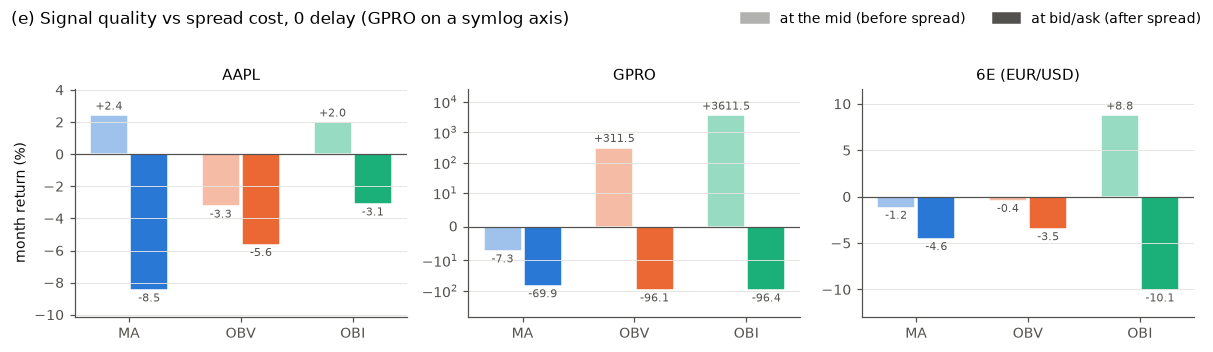

In [13]:
z = pnl.xs(0, level="delay")[["mid_return_pct", "return_pct"]]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, label in zip(axes, SECURITIES):
    zz = z.loc[label]
    x = np.arange(len(SIGNALS))
    for off, col, s in [(-0.18, "mid_return_pct", 0.45), (0.18, "return_pct", 1.0)]:
        bars = ax.bar(x + off, zz[col], 0.34, color=[shade(SIG_COLOR[g], s) for g in SIGNALS],
                      edgecolor="white", linewidth=1)
        ax.bar_label(bars, fmt="%+.1f", fontsize=7, color=MUTED, padding=2)
    if zz.abs().max().max() > 100:   # GPRO: OBI at the mid is +3,600%, so use a symlog axis
        ax.set_yscale("symlog", linthresh=10)
    ax.axhline(0, color=MUTED, lw=0.8)
    ax.set_xticks(x, SIGNALS)
    ax.set_title(label)
    ax.grid(axis="x", visible=False)
    ax.margins(y=0.15)
axes[0].set_ylabel("month return (%)")
handles = [plt.Rectangle((0, 0), 1, 1, color=shade(MUTED, s)) for s in (0.45, 1.0)]
fig.legend(handles, ["at the mid (before spread)", "at bid/ask (after spread)"], loc="upper right", ncol=2)
fig.suptitle("(e) Signal quality vs spread cost, 0 delay (GPRO on a symlog axis)",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.95))
save(fig, "e_mid_vs_touch")

## (f) Cost of delay

As in the paper's Figure 6, the cost of delay is the change in the strategy's month
return when it executes with a delay instead of instantly:

$$\text{CoD}(d) = R(d) - R(0) \quad \text{(percentage points of the \$1M book)}$$

so it starts at 0 at zero delay, and a negative number is a loss caused by being
slow. Figure 6 in the paper plots this against the delay grid
0 / 10 / 20 / 50 / 100 / 200 / 500 ms / 1 s. The same grid is used here, with the
two required delays marked.

Percentage points of the book understate the cost once a book has shrunk: GPRO
loses most of its capital to the spread, so later trades are small. The bottom row
therefore also shows the cost **per round trip**, in bp:
avg trade return(d) − avg trade return(0). That measure doesn't depend on
compounding, so it can be compared across assets.

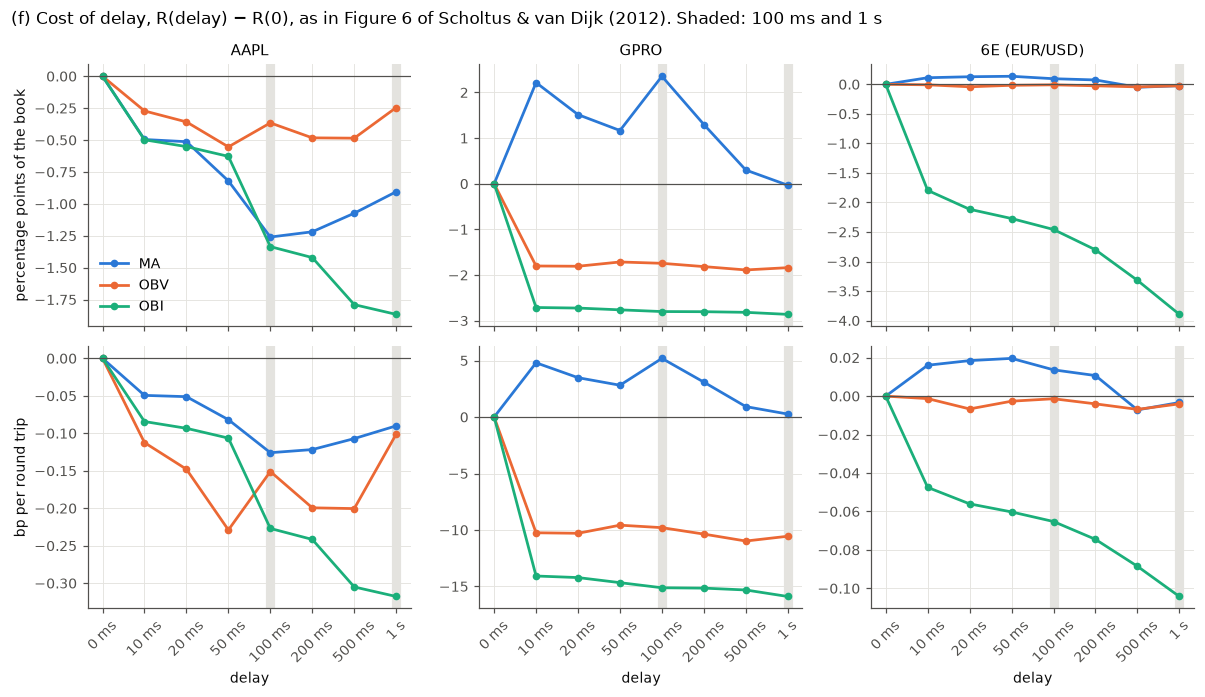

In [14]:
base = lambda col: reports[col].xs(0, level="delay").reindex(reports.index.droplevel("delay")).values
cod = pd.DataFrame({
    "cod_pp": reports.return_pct - base("return_pct"),
    "cod_bp_per_trade": reports.avg_trade_bp - base("avg_trade_bp"),
})
cod["cod_usd"] = cod.cod_pp / 100 * BOOK
cod.to_csv(OUT / "f_cost_of_delay_full_grid.csv")

fig, axes = plt.subplots(2, 3, figsize=(11, 6.4), sharex=True)
xs = np.arange(len(DELAY_GRID))
for row, (col, ylab) in enumerate([("cod_pp", "percentage points of the book"),
                                   ("cod_bp_per_trade", "bp per round trip")]):
    for ax, label in zip(axes[row], SECURITIES):
        for sig in SIGNALS:
            ax.plot(xs, cod.loc[(label, sig), col].values, color=SIG_COLOR[sig], marker="o", ms=4, label=sig)
        for d in (100, 1000):
            ax.axvline(DELAY_GRID.index(d), color=GRID, lw=6, zorder=0)
        ax.axhline(0, color=MUTED, lw=0.8)
        if row == 0:
            ax.set_title(label)
        else:
            ax.set_xticks(xs, [ms_label(d) for d in DELAY_GRID], rotation=45)
            ax.set_xlabel("delay")
    axes[row, 0].set_ylabel(ylab)
axes[0, 0].legend()
fig.suptitle("(f) Cost of delay, R(delay) − R(0), as in Figure 6 of Scholtus & van Dijk (2012). "
             "Shaded: 100 ms and 1 s", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
save(fig, "f_cost_of_delay")

The two required delays, as a table: cost in percentage points of the book, in
dollars, and in bp per round trip.

In [15]:
cod_req = cod.loc[(slice(None), slice(None), [100, 1000]), :].unstack("delay")
cod_req.columns = [f"{a}_{ms_label(b).replace(' ', '')}" for a, b in cod_req.columns]
cod_req = cod_req[sorted(cod_req.columns, key=lambda c: (c.split("_")[1], "1s" in c))]
cod_req.to_csv(OUT / "f_cost_of_delay.csv")
cod_req.style.format({c: ("${:+,.0f}" if "usd" in c else "{:+.3f}") for c in cod_req.columns})

## Commentary

### Market conditions

Each day is split at the month's median by two measures:
* **Volatility**: the standard deviation of 1-minute mid returns.
* **Trend efficiency**: |open-to-close move| ÷ the sum of absolute 1-minute moves.
  It is near 1 on a day that moves steadily one way and near 0 on a choppy day.

The table gives the average daily return (%, 0 delay, after spread costs) in each
half.

In [16]:
day_ret = (all_legs[all_legs.delay == 0].groupby(["security", "signal", "day"])
           .r.apply(lambda r: np.prod(1 + r) - 1).unstack("signal").reindex(columns=SIGNALS))
day_ret = day_ret.reindex(pd.MultiIndex.from_product([list(SECURITIES), DAYS], names=["security", "day"]),
                          fill_value=0.0) * 100
cond = stats.set_index(["security", "day"])[["vol_1min_bp", "trend_eff"]]
cond["vol"] = cond.groupby(level=0).vol_1min_bp.transform(lambda v: np.where(v > v.median(), "high vol", "low vol"))
cond["trend"] = cond.groupby(level=0).trend_eff.transform(lambda v: np.where(v > v.median(), "trending", "choppy"))
regimes = pd.concat({
    k: day_ret.join(cond[k]).groupby([pd.Grouper(level=0), k])[SIGNALS].mean().unstack(k)
    for k in ["vol", "trend"]}, axis=1)
regimes.to_csv(OUT / "commentary_regimes.csv")
regimes.round(3)

vol                                              trend  \
                   MA              OBV               OBI              MA   
             high vol low vol high vol  low vol high vol low vol  choppy   
security                                                                   
6E (EUR/USD)  -0.2330 -0.2110  -0.1140  -0.2180  -0.4070 -0.5940 -0.2840   
AAPL          -0.1160 -0.6760  -0.0920  -0.4370   0.2020 -0.4610 -0.9280   
GPRO          -9.0690 -1.6250 -13.9770 -13.6600 -21.4690 -5.2930 -5.1540   

                                                           
                           OBV               OBI           
             trending   choppy trending   choppy trending  
security                                                   
6E (EUR/USD)  -0.1530  -0.2510  -0.0780  -0.5510  -0.4540  
AAPL           0.1610  -0.1840  -0.3690   0.3460  -0.6860  
GPRO          -5.1870 -16.4480 -10.9090 -16.7120  -8.9080

### Tick frequency and the cost of delay

Each market's event rate, set against what a delayed entry costs, in bp, at 100 ms
and 1 s. The cost is split into two parts:
* `mid`: the mid moved in the direction of the trade before the fill
* `fill`: the full change in the price paid, which adds any change in the half-spread

In [17]:
tick = summary[["events_per_sec", "median_gap_ms", "spread_bp"]].copy()
for d in (100, 1000):
    tag = ms_label(d).replace(" ", "")
    tick[f"pct_moved_{tag}"] = dr[dr.delay == d].groupby("security").p_moved.mean() * 100
    for col, name in [("adverse_bp", "mid"), ("shortfall_bp", "fill")]:
        m = dr[dr.delay == d].pivot(index="security", columns="signal", values=col)[SIGNALS]
        tick = tick.join(m.add_prefix(f"{name}_{tag}_"))
tick.to_csv(OUT / "commentary_tick_frequency.csv")
tick.T.round(3)

security,AAPL,GPRO,6E (EUR/USD)
events_per_sec,40.3580,2.4430,26.5430
median_gap_ms,0.0320,2.0190,0.1320
spread_bp,0.9040,76.0460,0.4330
pct_moved_100ms,42.9810,14.0730,10.4760
mid_100ms_MA,-0.0080,0.0160,-0.0090
mid_100ms_OBV,0.0270,6.7430,-0.0040
mid_100ms_OBI,0.0250,8.0860,0.0230
fill_100ms_MA,0.0280,-2.5490,-0.0070
fill_100ms_OBV,0.0670,4.8970,0.0010
fill_100ms_OBI,0.0600,7.5460,0.0330


### Discussion

**The headline.** No signal makes money after crossing the spread, on any of the three
securities. Several do predict prices: before spread costs, MA and OBI are positive on
AAPL and OBI is positive on 6E and GPRO. The spread is the first-order cost and delay
is the second-order one. That ordering is what decides which assets and signals are
hurt by being slow.

**(a) Which asset is hurt most by delay, and why?**
The cost of delay is roughly
*(how often the price moves before the fill) × (how big a move is) × (how many
trades)*.

* **GPRO is hurt most per trade**: 10–15 bp per round trip for OBV and OBI, against
  0.1–0.3 bp for AAPL and below 0.1 bp for 6E. At ~\$1.30, its 1-cent tick is ~76 bp,
  so a single price change is enormous. Its mid moves before the fill in only ~14% of
  signals, but when it does it moves by half a tick or more. Almost all of the
  cost is already there at 10 ms: OBI and OBV fire *because* the queue at the touch is
  about to be eaten, so the race is lost within milliseconds, not seconds.
* **AAPL is the most "Figure 6-like"**: the mid has moved before the fill in ~43% of
  signals at 100 ms and ~72% at 1 s, but each move is a cent or two (~0.3 bp). The cost
  adds up to 1–2 percentage points of the book over the month for MA and OBI.
* **6E barely notices delay for the slow rules.** MA and OBV cost under 0.02 bp per
  trade even at 1 s, which is noise. The book updates ~27 times a second, but most
  updates change size, not price: the mid has moved in only ~10% of 100 ms windows.
  OBI still loses 2.5 points at 100 ms and 3.9 points at 1 s, and the reason is
  turnover, not any one trade. It trades ~200 times a day, so 0.07–0.10 bp per trade
  compounds over 4,249 round trips.

Compared with the paper: its Figure 6 is flat-to-noisy up to 200 ms and then falls to
−2.5% at 1 s. AAPL OBI and 6E OBI have the same shape: a steadily falling curve
reaching −1.9 and −3.9 points at 1 s. The slow rules (MA, OBV) look like the noisy
left part of the paper's curve. Their positions last minutes, so a fill a second
late changes little. GPRO MA even gains from delay, but on 151 trades in a large-tick
stock that's noise, not a real effect.

**(b) Do the signals behave differently in different market conditions?**
Yes, and in the way their design predicts (see the regime table; each half is only
~10 days, so treat this as suggestive):

* **MA is a trend rule**: on AAPL it makes +0.16%/day on trending days and loses
  −0.93%/day on choppy days, when it is whipsawed back and forth across the band.
* **OBI needs movement**: on AAPL it is positive on high-volatility days (+0.20%/day)
  and negative on quiet ones (−0.46%/day). It predicts moves of a few seconds, and only
  on volatile days are those moves big enough to pay the ~1 bp spread.
* **OBV has no edge at this horizon**: it loses even at the mid on AAPL and 6E.
  Signing volume by the tick direction is a slow, daily-bar idea that doesn't carry
  over to seconds.
* **On GPRO everything loses, and the volatile early-September run is the worst
  period** (Sep 1–4: ~27k trades a day, and a run from \$1.20 to \$2.00). More
  activity means more signals, and every signal pays 76 bp. The interesting
  counterpoint: priced at the mid, OBI on GPRO compounds to +3,600%. In a large-tick
  stock, queue imbalance predicts the next tick almost perfectly, but the predicted
  move is half a tick and taking it costs a full tick.

**(c) Does tick frequency matter, and how would we use it?**
The raw event rate is the wrong measure: 6E updates almost as often as AAPL, but its
delay cost per trade is several times smaller. What matters is the rate at which the
**price** changes, times the size of each change relative to the strategy's expected
profit per trade. In practice:

1. **Measure how fast the signal's edge decays** (the part (d) chart, done per
   signal), and only trade signals whose edge lasts much longer than our latency.
   With 1 s infrastructure, MA on 6E is fine; OBI anywhere is not.
2. **Add the expected delay cost to the entry threshold**: trade only when the
   expected move is larger than the spread plus *P(price changes within the
   latency) × the expected move*. That cost is far higher on GPRO than on 6E.
3. **Cut turnover where small per-trade costs multiply** (6E OBI): require a minimum
   holding time, or smooth over a longer window.
4. **In large-tick markets, stop paying the spread.** The GPRO imbalance signal is
   a good signal for *where to rest a limit order*, not for when to cross.

**Caveats.** One month of data. Every order is assumed to fill in full at the touch;
that is unrealistic for \$1M of GPRO, where the touch holds a few thousand dollars, so
the real GPRO results would be worse. Equity quotes are Nasdaq-only rather than the
consolidated NBBO. There are no fees or rebates. Signal parameters were fixed before
the full-month run, chosen for turnover, not optimised for returns.